# V_px_en_cols_distintas: p separadas en viga y cantonera

Nueva parametrizacion sobre el dataset ajustado:

- `p_viga`: distancias de la rama de viga; se decodifica con su propia GRU.
- `p_cantonera`: distancias de la rama de cantonera; se decodifica con su propia GRU.
- `n_viga` y `n_cantonera`: cabezas de clasificacion.
- `bottom_margin`: regresion one-shot desde el final de la cantonera (o fondo de viga) a la fila inferior.
- `Lh` no es input del modelo.
- Sin cabeza `has_cantonera`.
- Early stopping sobre `CFG["select_metric"]`.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import copy
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split

from core import adapter
from core.config import *
from core.dataset import (
    Preprocessor,
    ConnectionDataset,
    validate_connection_targets,
    validate_transition_labels,
)
from core.model import (
    ConnectionDesignNet,
    ConnectionDesignNetV4,
    ConnectionDesignNetV14,
    ConnectionDesignNetZones,
    n_bins_from_train,
    p_confidence,
)
from core.losses import (
    ConnectionDesignLoss,
    ConnectionDesignLossV4,
    ConnectionDesignLossV14,
    ConnectionDesignLossZones,
)
from core.training import fit, predict_loader
from core.postprocess import (
    decode_predictions,
    decode_zone_predictions,
    derive_dependent_columns,
)
from core.evaluation import (
    preparar_para_evaluar,
    evaluar_predicciones,
    evaluar_estructura,
    evaluar_sesgo_p,
    evaluar_acumulado_y,
    evaluar_por_transicion,
    resumen_p,
    contribucion_error_topologia,
    calibracion_confianza_p,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

## 1. Configuración

| clave de `CFG` | valores | efecto |
|---|---|---|
| `model` | `"v3"` / `"v4"` | v3 = regresión de p; v4 = p discretizada en bins de 5 mm |
| `joint_topology` | `True` / `False` | solo v4: una softmax conjunta sobre (n_alma, n_cantonera) |
| `class_weights` | `True` / `False` | pesos inversos a la frecuencia en los conteos |
| `select_metric` | `"val_loss"`, `"p_and_topology"`, `"p_within_10"`, `"p_mae_mm"`, `"topology_exact"` | criterio para elegir la mejor época (validación realista) |
| `w_p_ce`, `label_scale_bins` | números | peso de la cross-entropy de p y suavizado ordinal de la etiqueta (solo v4) |

In [3]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = Path("data/datos_modelo.parquet")
OUTPUT_DIR = Path("artifacts_px_en_cols_distintas")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_px_en_cols_distintas.pt"

BATCH_SIZE = 128
EPOCHS = 200
EARLY_STOPPING_PATIENCE = 30
EARLY_STOPPING_MIN_DELTA = 1e-4
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

HIDDEN_DIM = 192
NUM_BLOCKS = 3
DROPOUT = 0.10
GRU_HIDDEN_DIM = 128

DEFAULT_CFG = dict(
    model="zones",
    joint_topology=False,
    class_weights=False,
    select_metric="p_and_geometry",
    w_p_viga=2.0,
    w_p_cantonera=2.0,
    w_bottom_margin=1.0,
    w_n_viga=1.0,
    w_n_cantonera=1.0,
    w_geom=1.0,
    w_top=0.5,
    w_bottom=0.5,
    w_flange=0.5,
    label_scale_bins=1.0,
    temperature_mm=2.5,
)
CFG = {**DEFAULT_CFG}          # <- edita aqui el experimento principal

# --- Completado de columnas que faltan en el parquet ---
NORMATIVAS_FROM = "standard"   # de que columna sale `Normativas` si no existe
UNKNOWN_PROFILES = "drop"      # "drop": descarta filas con perfil fuera del catalogo | "error": para
# --- Particion ---
#   "inputs": agrupa filas con entradas identicas (evita fuga por duplicados)
#   "UNICODE": agrupa por UNICODE (en este parquet es unico por fila => equivale a aleatorio)
#   None: particion aleatoria simple
SPLIT_GROUP = "inputs"

RUN_DIAGNOSTICS = True         # cierre geometrico, multimodalidad, duplicados (necesita core/diagnostico_p.py)
RUN_ABLATION = False           # seccion 18 (lenta: 5 configuraciones x semillas)
ABLATION_SEEDS = [0, 1, 2]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Dispositivo:", DEVICE)
print("Experimento :", CFG)

Dispositivo: cuda
Experimento : {'model': 'zones', 'joint_topology': False, 'class_weights': False, 'select_metric': 'p_and_geometry', 'w_p_viga': 2.0, 'w_p_cantonera': 2.0, 'w_bottom_margin': 1.0, 'w_n_viga': 1.0, 'w_n_cantonera': 1.0, 'w_geom': 1.0, 'w_top': 0.5, 'w_bottom': 0.5, 'w_flange': 0.5, 'label_scale_bins': 1.0, 'temperature_mm': 2.5}


## 2. Carga del parquet

In [4]:
suffix = DATA_PATH.suffix.lower()
if suffix == ".parquet":
    df = pd.read_parquet(DATA_PATH)
elif suffix == ".csv":
    df = pd.read_csv(DATA_PATH)
elif suffix in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH)
else:
    raise ValueError(f"Formato no soportado: {suffix}")

df = df.reset_index(drop=True)
print("Dimensiones:", df.shape)

faltan_entrada = [c for c in CATEGORICAL_FEATURES + NUMERIC_FEATURES if c not in df.columns]
print("Columnas de entrada del modelo que NO estan en el parquet:", faltan_entrada)

Dimensiones: (4451, 58)
Columnas de entrada del modelo que NO estan en el parquet: []


## 3. Completar medidas de perfil y `Normativas`

Se reutiliza el catálogo de perfiles del `adapter` (`_profile_lookup`, indexado por nombre en mayúsculas y sin espacios), que es lo que usa producción. Así entrenamiento e inferencia ven exactamente las mismas medidas.

Notas:

- `adapter._add_profiles` solo rellena `*_type` y `*_d_mm`, aunque define `measures = ["d_mm", "b_mm", "tf_mm", "tw_mm"]`. Aquí se rellenan las cuatro medidas. **Producción necesita el mismo cambio**: `preprocess()` selecciona `FEATURE_COLUMNS` (que incluye `BEAM_b_mm`, `BEAM_tf_mm`, …) y fallará con `KeyError` porque esas columnas no se crean.
- Se comprueba que el `d_mm` del catálogo coincide con el del parquet (si no, los datos y el catálogo no son de la misma fuente).
- Se comprueba que `fy/fu` de acero y tornillo coinciden con `ACERO_TABLE` / `TORNILLO_TABLE`.
- **`Normativas`**: se copia de `standard`. El adapter ofrece como opciones de `Normativas` las clases de `standard`, y `standard` es a su vez una salida: el modelo aprenderá que `standard ≈ Normativas` (es lo esperado en producción, pero ese acierto no mide nada).

In [5]:
PROFILE_MEASURES = ["d_mm", "b_mm", "tf_mm", "tw_mm"]


def completar_perfiles(df, on_unknown="drop"):
    lookup = adapter._profile_lookup()
    faltan = [m for m in PROFILE_MEASURES if m not in lookup.columns]
    if faltan:
        raise KeyError(f"El catalogo Tekla no tiene las columnas {faltan}. Disponibles: {list(lookup.columns)}")

    df = df.copy()
    keep = np.ones(len(df), dtype=bool)
    for col in ("BEAM", "COLUMN"):
        keys = df[col].astype(str).str.strip().str.upper()
        known = keys.isin(lookup.index).to_numpy()
        if not known.all():
            unk = sorted(set(df.loc[~known, col].astype(str)))
            msg = f"{col}: {int((~known).sum())} filas con perfiles fuera del catalogo Tekla: {unk}"
            if on_unknown == "error":
                raise adapter.InputContractError(msg)
            print("AVISO ->", msg)
            keep &= known
        geom = lookup.reindex(keys)
        for m in PROFILE_MEASURES:
            new = pd.to_numeric(geom[m].to_numpy(), errors="coerce")
            if m == "d_mm" and f"{col}_d_mm" in df.columns:
                diff = np.abs(new - df[f"{col}_d_mm"].to_numpy(float))
                bad = np.nansum(diff > 1.0)
                print(f"{col}_d_mm: filas donde catalogo y parquet difieren > 1 mm: {int(bad)}")
                continue          # se conserva el d_mm del parquet
            df[f"{col}_{m}"] = new
    n0 = len(df)
    df = df.loc[keep].reset_index(drop=True)
    if n0 != len(df):
        print(f"Filas descartadas por perfil desconocido: {n0 - len(df)}")
    return df


if not adapter.DATA_DIR.exists():
    raise FileNotFoundError(f"No encuentro los catalogos Tekla en {adapter.DATA_DIR}. Ajusta adapter.DATA_DIR.")

df = completar_perfiles(df, on_unknown=UNKNOWN_PROFILES)

if "Normativas" not in df.columns:
    df["Normativas"] = df[NORMATIVAS_FROM].astype(str).str.strip()
    print(f"Normativas creada a partir de '{NORMATIVAS_FROM}':", df["Normativas"].value_counts().to_dict())

# Consistencia de materiales con las tablas del adapter
for col, table in (("grado_acero", adapter.ACERO_TABLE), ("clase_tornillo", adapter.TORNILLO_TABLE)):
    for prop in next(iter(table.values())):
        esperado = df[col].astype(str).str.strip().map(lambda v: table[v][prop])
        n_bad = int(((df[prop] - esperado).abs() > 1e-6).sum())
        print(f"{col} -> {prop}: filas inconsistentes con la tabla = {n_bad}")

nuevas = [c for c in NUMERIC_FEATURES if c.endswith(("_b_mm", "_tf_mm", "_tw_mm"))]
print("\nNulos en medidas nuevas:", df[nuevas].isna().sum().to_dict())
display(df[["BEAM", "COLUMN"] + nuevas].drop_duplicates().head(8))
if nuevas:
    display(df[nuevas].describe().T.round(1))

BEAM_d_mm: filas donde catalogo y parquet difieren > 1 mm: 0
COLUMN_d_mm: filas donde catalogo y parquet difieren > 1 mm: 0
Normativas creada a partir de 'standard': {'EN 1993-1-8': 2585, 'AISC-360-05/10': 1773, 'CSA S16-09': 93}
grado_acero -> fy_acero_mpa: filas inconsistentes con la tabla = 0
grado_acero -> fu_acero_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fy_tornillo_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fu_tornillo_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fv_tornillo_mpa: filas inconsistentes con la tabla = 0

Nulos en medidas nuevas: {}


,BEAM,COLUMN
0,IPE300,HEA260
1,HEA180,HEA300
2,IPE300,HEA320
3,HEA200,HEA280
4,HEA240,HEA300
5,IPE330,HEA320
6,IPE300,HEA240
7,IPE300,HEA280


## 4. Validación del dataset

In [6]:
required_columns = (
    CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS
    + ["standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera", "BEAM_tf_mm"]
)
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Faltan columnas obligatorias: {missing}")

numeric_columns = list(dict.fromkeys(
    NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS + ["n_alma", "n_cantonera", "BEAM_tf_mm"]
))
for c in numeric_columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df[MASKED_COLUMNS] = df[MASKED_COLUMNS].fillna(0.0)
essential = CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + [
    "standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera", "BEAM_tf_mm"
]
before = len(df)
df = df.dropna(subset=essential).reset_index(drop=True)
print(f"Filas eliminadas por nulos: {before - len(df)}")

bolt_numeric = df["Bolt"].astype(str).str.replace("M", "", regex=False).astype(int)
unknown_bolts = sorted(set(bolt_numeric) - set(CATALOGO_BOLT))
if unknown_bolts:
    raise ValueError(f"Bolt fuera de catalogo: {unknown_bolts}")

cv = validate_connection_targets(df)
print("Conexiones con prefijo y conteo coherentes:", cv["valid"].mean())
if not cv["valid"].all():
    df = df.loc[cv["valid"].to_numpy()].reset_index(drop=True)

lv = validate_transition_labels(df)
if lv is not None:
    print("Etiquetas de transicion coherentes:", lv.mean())
    if not lv.all():
        raise ValueError("Hay etiquetas de transicion incompatibles con la topologia.")
else:
    print("No hay columnas pX_transition: se derivan de n_alma y n_cantonera.")

vals = df[P_COLUMNS].to_numpy(float)
act = vals > 0
on_grid = np.mean(np.isclose(vals[act] % Y_GRID_STEP, 0) | np.isclose(vals[act] % Y_GRID_STEP, Y_GRID_STEP))
print(f"p activas en rejilla de {Y_GRID_STEP} mm: {100 * on_grid:.1f}%  (si es < ~98% revisa la rejilla)")

if "geometria_dudosa" in df.columns:
    print("Filas con geometria_dudosa=True:", int(df["geometria_dudosa"].sum()))
print("Filas finales:", len(df))
from core.postprocess import geometry_counts
_na_geo, _nc_geo = geometry_counts(
    df["e"].to_numpy(), df["d"].to_numpy(),
    df[P_COLUMNS].fillna(0).to_numpy(float),
    df["BEAM_d_mm"].to_numpy(), df["BEAM_tf_mm"].to_numpy(),
)
_label_mismatch = (_na_geo != df["n_alma"].to_numpy()) | (_nc_geo != df["n_cantonera"].to_numpy())
print(
    "Etiquetas n_alma/n_cantonera vs geometria: "
    f"{int(_label_mismatch.sum())} diferencias de {len(df)} filas"
)


Filas eliminadas por nulos: 0
Conexiones con prefijo y conteo coherentes: 1.0
Etiquetas de transicion coherentes: 1.0
p activas en rejilla de 5 mm: 98.4%  (si es < ~98% revisa la rejilla)
Filas con geometria_dudosa=True: 0
Filas finales: 4451
Etiquetas n_alma/n_cantonera vs geometria: 0 diferencias de 4451 filas


## 5. División entrenamiento / validación / prueba

En este parquet `UNICODE` es único por fila, así que agrupar por él no evita ninguna fuga. Con `SPLIT_GROUP = "inputs"` las filas con **entradas idénticas** (perfiles, ratios, materiales y normativa) caen siempre en la misma partición; así el test no contiene conexiones que el modelo ya vio con otra etiqueta.

In [7]:
if SPLIT_GROUP == "inputs":
    key_cols = ["BEAM", "COLUMN", "ratio_moment", "ratio_shear", "ratio_axial",
                "grado_acero", "clase_tornillo", "Normativas"]
    key = df[key_cols].astype(str).apply(lambda s: s.str.upper()).agg("|".join, axis=1)
    df["_grupo"] = pd.factorize(key)[0]
    GROUP_COLUMN = "_grupo"
elif SPLIT_GROUP:
    GROUP_COLUMN = SPLIT_GROUP
else:
    GROUP_COLUMN = None

if GROUP_COLUMN is not None:
    print(f"Grupos: {df[GROUP_COLUMN].nunique()} para {len(df)} filas")
    split_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    tv_idx, test_idx = next(split_test.split(df, groups=df[GROUP_COLUMN]))
    df_train_val = df.iloc[tv_idx].reset_index(drop=True)
    df_test = df.iloc[test_idx].reset_index(drop=True)
    split_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
    tr_idx, va_idx = next(split_val.split(df_train_val, groups=df_train_val[GROUP_COLUMN]))
    df_train = df_train_val.iloc[tr_idx].reset_index(drop=True)
    df_val = df_train_val.iloc[va_idx].reset_index(drop=True)
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_val[GROUP_COLUMN]))
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_test[GROUP_COLUMN]))
else:
    df_train_val, df_test = train_test_split(df, test_size=0.15, random_state=SEED)
    df_train, df_val = train_test_split(df_train_val, test_size=0.1765, random_state=SEED)
    df_train, df_val, df_test = [d.reset_index(drop=True) for d in (df_train, df_val, df_test)]

print("Train:", len(df_train), "| Val:", len(df_val), "| Test:", len(df_test))

for name, other in [("validacion", df_val), ("test", df_test)]:
    unk = {c: sorted(set(other[c].astype(str)) - set(df_train[c].astype(str))) for c in CATEGORICAL_FEATURES}
    unk = {c: v for c, v in unk.items() if v}
    print(f"Categorias desconocidas en {name}:", unk)
    if unk:
        raise ValueError("LabelEncoder no admite categorias desconocidas.")

print("\nDistribucion de la normativa por particion (%)")
display(pd.DataFrame({n: d["Normativas"].value_counts(normalize=True) * 100
                      for n, d in [("train", df_train), ("val", df_val), ("test", df_test)]}).round(1))

Grupos: 4386 para 4451 filas
Train: 3115 | Val: 671 | Test: 665
Categorias desconocidas en validacion: {}
Categorias desconocidas en test: {}

Distribucion de la normativa por particion (%)


,train,val,test
Normativas,,,
EN 1993-1-8,58.6,55.3,58.3
AISC-360-05/10,39.1,42.8,40.2
CSA S16-09,2.2,1.9,1.5


## 6. Diagnósticos previos (opcional, sobre entrenamiento)

Requiere `core/diagnostico_p.py`. Si no existe se omite.

In [8]:
if RUN_DIAGNOSTICS:
    try:
        from core.diagnostico_p import cierre_geometrico, multimodalidad, duplicados_entrada
        print("CIERRE GEOMETRICO (filas 'todas' primero)")
        cg = cierre_geometrico(df_train)
        display(cg[cg.grupo == "todas"])
        print("MULTIMODALIDAD POR TRANSICION")
        display(multimodalidad(df_train))
        print("SUELO DE RUIDO (entradas identicas)")
        display(duplicados_entrada(df_train))
    except ImportError:
        print("core/diagnostico_p.py no encontrado: se omiten los diagnosticos.")

CIERRE GEOMETRICO (filas 'todas' primero)


,total,grupo,N,pendiente,residuo_std_mm,residuo_MAE_mm,pct_residuo_<=5mm
0,sum(p),todas,3115,1.63,132.32,120.60,0.0
13,e + sum(p),todas,3115,1.65,132.08,120.27,0.0
26,e + sum(p) + d,todas,3115,1.69,131.42,119.20,0.0


MULTIMODALIDAD POR TRANSICION


,transicion,N,valores_distintos,media,std,pct_en_rejilla_5,top1_pct,top3_pct
11,superior__viga primero,3080,34,117.03,23.33,99.12,13.57,34.35
25,viga primero__viga inferior,1829,38,97.98,33.52,99.07,13.94,34.17
22,viga inferior__inferior,1492,20,118.27,23.83,100.00,15.28,39.14
21,viga inferior__cantonera primero,1214,48,163.88,42.20,98.43,10.21,27.92
6,cantonera inferior__inferior,1214,33,136.06,21.92,98.35,15.65,42.42
19,viga centro__viga inferior,1038,43,129.20,48.91,100.00,12.24,29.00
23,viga primero__viga centro,1038,27,107.61,36.12,100.00,10.31,30.35
9,cantonera primero__cantonera inferior,917,28,86.28,25.90,97.82,15.49,41.33
5,cantonera centro__inferior,374,14,116.97,11.64,100.00,41.18,69.79
20,viga inferior__cantonera centro,374,18,130.93,25.93,99.73,22.73,56.15


SUELO DE RUIDO (entradas identicas)


,p,N_en_duplicados,MAE_vs_mediana_grupo_mm,pct_dentro_10mm
0,p1,226,6.81,85.84
1,p2,226,16.08,38.94
2,p3,226,30.88,14.16
3,p4,176,22.29,46.59
4,p5,102,46.35,9.80
5,p6,24,54.27,0.00
6,p7,12,66.67,0.00
7,p8,2,80.00,0.00


## 7. Preprocesador, datasets y loaders

In [9]:
pre = Preprocessor().fit(df_train)
train_dataset = ConnectionDataset(df_train, pre)
val_dataset = ConnectionDataset(df_val, pre)
test_dataset = ConnectionDataset(df_test, pre)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kw)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kw)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kw)

N_BINS = n_bins_from_train(df_train, P_COLUMNS, step_mm=Y_GRID_STEP)
print(f"Bins de p: {N_BINS} (hasta {(N_BINS - 1) * Y_GRID_STEP} mm, paso {Y_GRID_STEP} mm)")
print("Features numericas:", len(NUMERIC_FEATURES), "| categoricas:", CATEGORICAL_FEATURES)


Bins de p: 64 (hasta 315 mm, paso 5 mm)
Features numericas: 10 | categoricas: []


## 8. Construcción del modelo, decodificación y utilidades

In [10]:
def build_experiment(cfg):
    model_kw = dict(
        cat_cardinalities=pre.cat_cardinalities,
        num_continuous=len(NUMERIC_FEATURES),
        n_standard_classes=pre.n_standard_classes,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        hidden_dim=HIDDEN_DIM,
        num_blocks=NUM_BLOCKS,
        dropout=DROPOUT,
        gru_hidden_dim=GRU_HIDDEN_DIM,
        previous_p_scale_mm=200.0,
        cumulative_scale_mm=1000.0,
    )
    w_alma = pre.count_class_weights["n_alma"] if cfg["class_weights"] else np.ones(N_ALMA_CLASSES, np.float32)
    w_cant = pre.count_class_weights["n_cantonera"] if cfg["class_weights"] else np.ones(N_CANTONERA_CLASSES, np.float32)
    loss_kw = dict(
        n_alma_weights=w_alma,
        n_cantonera_weights=w_cant,
        presence_pos_weight=pre.presence_pos_weight,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        w_cls=1.0, w_counts=1.0, w_reg=1.0,
        w_p_value=2.0, w_p_cumulative=0.1,
        w_stiffener_value=1.0, w_masked_presence=0.5,
        cumulative_scale_mm=20.0, p_tolerance_mm=10.0,
    )
    if cfg["model"] == "v3":
        model = ConnectionDesignNet(**model_kw)
        criterion = ConnectionDesignLoss(**loss_kw)
    elif cfg["model"] == "v12":
        model = ConnectionDesignNetV4(**model_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                      joint_topology=cfg["joint_topology"])
        criterion = ConnectionDesignLossV4(**loss_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                           joint_topology=cfg["joint_topology"],
                                           w_p_ce=cfg["w_p_ce"], label_scale_bins=cfg["label_scale_bins"])
    elif cfg["model"] == "zones":
        model = ConnectionDesignNetZones(
            **model_kw,
            n_p_bins=N_BINS,
            p_bin_step_mm=Y_GRID_STEP,
            reg_mean_mm=pre.reg_always_scaler.mean_,
            reg_std_mm=pre.reg_always_scaler.scale_,
        )
        criterion = ConnectionDesignLossZones(
            **loss_kw,
            n_p_bins=N_BINS,
            p_bin_step_mm=Y_GRID_STEP,
            w_p_viga=cfg["w_p_viga"],
            w_p_cantonera=cfg["w_p_cantonera"],
            w_bottom_margin=cfg["w_bottom_margin"],
            w_n_viga=cfg["w_n_viga"],
            w_n_cantonera=cfg["w_n_cantonera"],
            w_geom=cfg["w_geom"],
            w_top=cfg["w_top"],
            w_bottom=cfg["w_bottom"],
            w_flange=cfg["w_flange"],
            label_scale_bins=cfg["label_scale_bins"],
            temperature_mm=cfg["temperature_mm"],
            reg_mean_mm=pre.reg_always_scaler.mean_,
            reg_std_mm=pre.reg_always_scaler.scale_,
        )
    else:
        raise ValueError(cfg["model"])

    return model.to(DEVICE), criterion.to(DEVICE)


CATALOGS = {"g": CATALOGO_g, "e": CATALOGO_e, "d": CATALOGO_d, "Bp": CATALOGO_Bp, "tp": CATALOGO_tp,
            "tws": CATALOGO_tws, "ts": CATALOGO_ts, "tbs": CATALOGO_tbs, "tst": CATALOGO_tst}


def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30.0, 30.0)))


def snap_to_catalog(values, catalog):
    values = np.asarray(values, dtype=float)
    if catalog is None:
        return values
    catalog = np.asarray(catalog, dtype=float)
    return catalog[np.abs(values[:, None] - catalog[None, :]).argmin(axis=1)]


def decode_outputs(outputs, preprocessor, df):
    reg = preprocessor.inverse_reg_always(outputs["reg_always"])
    masked = preprocessor.inverse_masked(outputs["masked_value"])
    presence = sigmoid_np(outputs["masked_presence_logit"])
    result = decode_zone_predictions(
        reg_always_real=reg,
        masked_value_real=masked,
        masked_presence_prob=presence,
        bolt_logits=outputs["bolt_logits"],
        n_viga_logits=outputs["n_viga_logits"],
        n_cantonera_logits=outputs["n_cantonera_logits"],
        p_viga_mm=outputs["p_viga_mm"],
        p_cantonera_mm=outputs["p_cantonera_mm"],
        bottom_margin_mm=outputs["bottom_margin_mm"],
        beam_d_mm=df["BEAM_d_mm"].to_numpy(),
        beam_tf_mm=df["BEAM_tf_mm"].to_numpy(),
        standard_logits=outputs["standard_logits"],
        standard_classes=preprocessor.standard_encoder.classes_,
        slip_critical_logit=outputs["slip_critical_logit"],
    )
    return derive_dependent_columns(result).drop(columns=["_bolt_nominal_mm"], errors="ignore")


def predict_designs(model, loader, df):
    out_true = predict_loader(model, loader, DEVICE, use_true_transitions=True)
    out_real = predict_loader(model, loader, DEVICE, use_true_transitions=False)
    return out_true, out_real, decode_outputs(out_true, pre, df), decode_outputs(out_real, pre, df)


def kpis(df_eval, design_real, design_true):
    r = resumen_p(df_eval, design_real)
    t = resumen_p(df_eval, design_true)
    ok = ((df_eval["n_alma"].astype(int).to_numpy() == design_real["n_alma"].astype(int).to_numpy())
          & (df_eval["n_cantonera"].astype(int).to_numpy() == design_real["n_cantonera"].astype(int).to_numpy()))
    return {
        "p_MAE_mm": r["MAE_mm"],
        "p_pct_10mm": r["pct_<=10mm"],
        "p_pct_>20mm": r["pct_>20mm"],
        "p99_mm": r["p99_abs_mm"],
        "topologia_exacta_%": 100 * ok.mean(),
        "p_pct_10mm_topologia_real": t["pct_<=10mm"],
    }


## 9. Prueba de una pasada antes de entrenar

In [11]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
print(f"Parametros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

sample = next(iter(train_loader))
x_cat = sample["x_cat"].to(DEVICE)
x_num = sample["x_num"].to(DEVICE)
targets = {k: v.to(DEVICE) for k, v in sample.items() if k not in {"x_cat", "x_num"}}
with torch.no_grad():
    out = model(
        x_cat, x_num,
        p_viga_teacher=targets["p_viga"],
        p_cantonera_teacher=targets["p_cantonera"],
        teacher_forcing_ratio=1.0,
        beam_d_mm=targets["beam_d_mm"],
        beam_tf_mm=targets["beam_tf_mm"],
    )
    loss0, parts0 = criterion(out, targets)
print("Loss inicial:", float(loss0))
assert torch.isfinite(loss0), "La perdida inicial no es finita: revisa NaN en las features"
for k, v in out.items():
    print(f"{k:28s}", tuple(v.shape))

Parametros entrenables: 668,082
Loss inicial: 74.88217163085938
standard_logits              (128, 3)
bolt_logits                  (128, 7)
slip_critical_logit          (128,)
n_viga_logits                (128, 7)
n_alma_logits                (128, 7)
n_cantonera_logits           (128, 6)
p_viga_logits                (128, 6, 64)
p_cantonera_logits           (128, 5, 64)
p_viga_mm                    (128, 6)
p_cantonera_mm               (128, 5)
bottom_margin_mm             (128, 1)
reg_always                   (128, 5)
masked_value                 (128, 16)
masked_presence_logit        (128, 16)


## 10. Entrenamiento

La mejor época se elige con `CFG["select_metric"]` sobre **validación realista** (topología predicha, sin teacher forcing).

Se aplica **early stopping** si `CFG["select_metric"]` no mejora durante `EARLY_STOPPING_PATIENCE` ?pocas, con una mejora m?nima `EARLY_STOPPING_MIN_DELTA`. Se restauran los pesos de la mejor ?poca.


In [12]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
t0 = time.time()
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    checkpoint_path=BEST_CHECKPOINT,
    log_every=10,
    tf_start=1.0,
    tf_end=0.15,
    tf_warmup_fraction=0.15,
    select_metric=CFG["select_metric"],
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoca 001/200 | LR 8.53e-05 | TF 100.0% | Train  71.6244 | Val  71.8254 | Mejor  71.8254 [MEJOR] | sel=p_and_geometry
  p       | loss train/val  0.391/ 0.517 | CE    nan/   nan | acumulada  4.329/ 4.281 | MAE  38.17 mm | <=10 mm  23.4%
  geometria | MAE acumulado  63.10 mm | reg  0.469 | rigidizadores  0.549 | presencia  0.972
  topologia | n_viga  1.647 | n_cantonera  1.772 | conjunta    nan | exacta  16.0%
  conteos  | exactos  52.0% | n_rows   0.0% | arriba   0.0% | abajo   0.0%
  clases  | standard  0.752 | bolt  1.873 | slip  0.509
Epoca 004/200 | LR 1.63e-04 | TF 100.0% | Train  60.6151 | Val  59.9316 | Mejor  59.9316 [MEJOR] | sel=p_and_geometry
  p       | loss train/val  0.394/ 0.517 | CE    nan/   nan | acumulada  4.270/ 4.281 | MAE  26.75 mm | <=10 mm  39.5%
  geometria | MAE acumulado  63.10 mm | reg  0.254 | rigidizadores  0.427 | presencia  0.957
  topologia | n_viga  0.668 | n_cantonera  1.063 | conjunta    nan | exacta  43.0%
  conteos  | exactos  65.4% | n_rows   0.0%

## 11. Curvas de entrenamiento

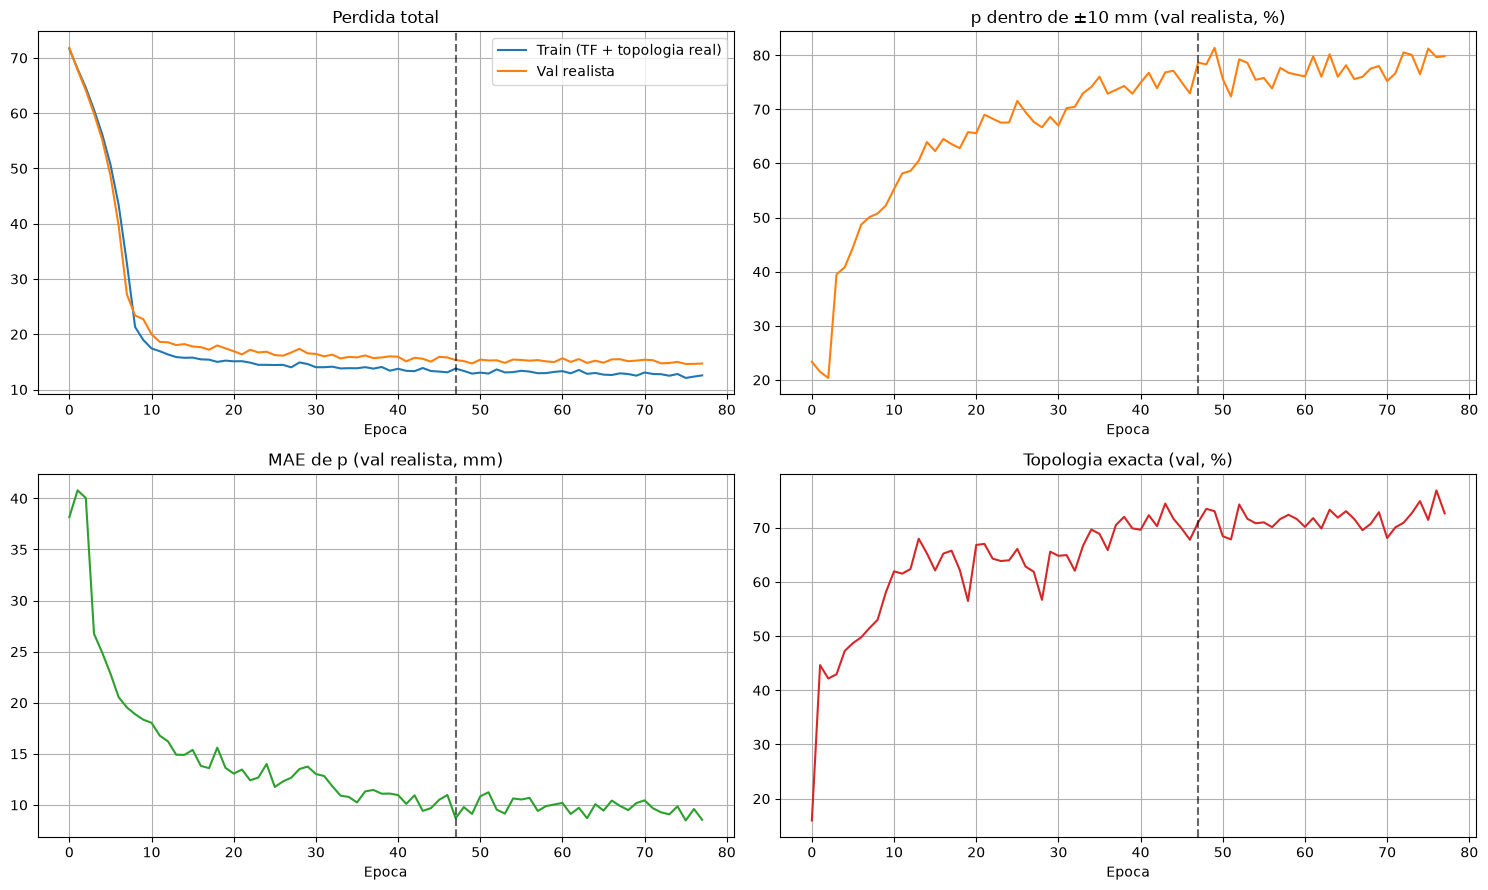

Mejor epoca: 48 | criterio: p_and_geometry


In [13]:
def curve(key, scale=1.0):
    return [scale * x.get(key, np.nan) for x in history["val_parts"]]

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0, 0].plot(history["train_loss"], label="Train (TF + topologia real)")
ax[0, 0].plot(history["val_loss"], label="Val realista")
ax[0, 0].set_title("Perdida total"); ax[0, 0].legend()
ax[0, 1].plot(curve("p_within_10", 100), color="tab:orange")
ax[0, 1].set_title("p dentro de ±10 mm (val realista, %)")
ax[1, 0].plot(curve("p_mae_mm"), color="tab:green")
ax[1, 0].set_title("MAE de p (val realista, mm)")
ax[1, 1].plot(curve("topology_exact", 100), color="tab:red")
ax[1, 1].set_title("Topologia exacta (val, %)")
for a in ax.ravel():
    a.axvline(history["best_epoch"] - 1, color="black", linestyle="--", alpha=0.6)
    a.set_xlabel("Epoca"); a.grid(True)
plt.tight_layout(); plt.show()
print("Mejor epoca:", history["best_epoch"], "| criterio:", history["select_metric"])

## 12. Predicción en test y comparación validación vs. test

La época se elige con validación, así que la validación está algo optimista. Si la diferencia con test es grande, hay sobreajuste a la selección (o un test pequeño: ~700 filas, diferencias de ±1,5 puntos son ruido).

In [14]:
out_true, out_real, design_true, design_real = predict_designs(model, test_loader, df_test)
display(design_real.head())

_, _, val_true, val_real = predict_designs(model, val_loader, df_val)
display(pd.DataFrame({"validacion": kpis(df_val, val_real, val_true),
                      "test": kpis(df_test, design_real, design_true)}).round(2))

,g,e,d,Bp,tp,n_alma,n_viga,n_cantonera,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,tws,ts,tbs,tst,Bolt,standard,SlipCritical,p1_transition,p2_transition,p3_transition,p4_transition,p5_transition,p6_transition,p7_transition,p8_transition,p9_transition,p10_transition,p11_transition,p12_transition,Hole,num_filas_tornillos,tiene_cantonera
0,110.0,40.0,38.885677,182.0,20.0,3,3,2,90.0,55.0,205.0,90.0,160.0,75.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,12.0,12.0,0.0,20,AISC-360-05/10,NO,superior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,22,7,True
1,125.0,40.0,48.437157,292.0,20.0,2,2,2,110.0,70.0,180.0,70.0,190.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,10.0,15.0,0.0,24,AISC-360-05/10,NO,superior__viga primero,viga primero__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,26,6,True
2,110.0,40.0,40.190590,209.0,20.0,3,3,2,85.0,55.0,70.0,110.0,55.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,10.0,0.0,20,AISC-360-05/10,NO,superior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,22,7,True
3,125.0,40.0,46.783863,258.0,20.0,3,3,2,120.0,70.0,140.0,135.0,75.0,205.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,10.0,15.0,0.0,27,AISC-360-05/10,NO,superior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,29,7,True
4,95.0,40.0,36.730179,189.0,20.0,2,2,0,85.0,75.0,85.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,10.0,10.0,0.0,20,AISC-360-05/10,NO,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,22,4,False


,validacion,test
p_MAE_mm,18.27,17.24
p_pct_10mm,70.91,71.90
p_pct_>20mm,20.38,19.87
p99_mm,155.00,150.00
topologia_exacta_%,73.32,75.04
p_pct_10mm_topologia_real,70.38,71.28


## 13. Métricas de p

- **topología real** = lo que da la parte de p cuando la estructura está bien (techo);
- **inferencia realista** = lo que verá el usuario final;
- **colas** (`pct_>20mm`, `p95`, `p99`): donde está el problema de fiabilidad.

In [15]:
summary = pd.DataFrame({
    "topologia real": resumen_p(df_test, design_true),
    "inferencia realista": resumen_p(df_test, design_real),
})
display(summary.round(2))

,topologia real,inferencia realista
N_separaciones,3050.00,3050.00
MAE_mm,19.65,17.24
RMSE_mm,43.14,37.57
mediana_abs_mm,5.00,5.00
pct_<=5mm,63.80,63.93
pct_<=10mm,71.28,71.90
pct_>20mm,20.79,19.87
p95_abs_mm,115.00,100.00
p99_abs_mm,160.00,150.00


In [16]:
print("=== TOPOLOGIA REAL ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_true)
metrics_true = evaluar_predicciones(real_df, pred_df)

print("\n=== INFERENCIA REALISTA ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_real)
metrics_realistic = evaluar_predicciones(real_df, pred_df)

=== TOPOLOGIA REAL ===
Variable   N  MAE_mm  RMSE_mm      R2  pct_5mm  pct_10mm
       g 665   3.556    6.177   0.842   83.008    93.835
       e 665   1.180    2.637   0.740   97.895   100.000
       d 665   2.595    3.713   0.809   85.564    97.895
      Bp 665  21.543   30.056   0.676   25.865    40.752
      tp 665   1.430    2.918   0.734   98.797    99.699
      p1 665   4.517    8.775   0.859   73.233    89.774
      p2 665   9.825   25.030   0.487   72.932    78.346
      p3 659  20.562   41.698   0.027   64.340    67.982
      p4 478  30.035   54.758  -0.694   58.577    60.669
      p5 290  37.137   64.957  -2.990   44.138    53.448
      p6 174  47.925   73.475  -5.112   35.057    44.253
      p7  61  46.967   81.359  -8.607   49.180    54.098
      p8  23  18.478   52.409  -1.636   78.261    82.609
      p9  16   1.250    2.500   0.991  100.000   100.000
     p10  11   4.545    6.396   0.937   81.818    90.909
     p11   4   0.000    0.000     NaN  100.000   100.000
     p12

### Otras salidas categóricas

El reference solo evalúa geometría; aquí se añade el acierto de las clasificaciones (`standard`, `Bolt`, `SlipCritical`). Recuerda que `standard` es casi trivial porque `Normativas` se copió de él.

In [17]:
cls_rows = []
for col in ["standard", "Bolt", "SlipCritical"]:
    real_c = df_test[col].astype(str).str.replace("M", "", regex=False).to_numpy()
    pred_c = design_real[col].astype(str).to_numpy()
    cls_rows.append({"variable": col, "acierto_%": 100 * np.mean(real_c == pred_c)})
for col in ["tws", "ts", "tbs", "tst"]:
    real_pres = df_test[col].fillna(0).to_numpy() > 0
    pred_pres = design_real[col].to_numpy() > 0
    cls_rows.append({"variable": f"{col} (presencia)", "acierto_%": 100 * np.mean(real_pres == pred_pres)})
classification_metrics = pd.DataFrame(cls_rows)
display(classification_metrics.round(2))

,variable,acierto_%
0,standard,99.85
1,Bolt,81.65
2,SlipCritical,98.65
3,tws (presencia),35.49
4,ts (presencia),48.12
5,tbs (presencia),60.15
6,tst (presencia),82.41


## 14. Topología: exactitud, confusión y contribución al error de p

In [18]:
print("Exactitud de estructura:")
structure = evaluar_estructura(df_test, design_real)

real_na = df_test["n_alma"].astype(int).reset_index(drop=True)
real_nc = df_test["n_cantonera"].astype(int).reset_index(drop=True)
print("\nConfusion n_alma")
display(pd.crosstab(real_na.rename("real"), design_real["n_alma"].astype(int).rename("pred")))
print("Confusion n_cantonera")
display(pd.crosstab(real_nc.rename("real"), design_real["n_cantonera"].astype(int).rename("pred")))

print("Contribucion de la topologia al error de p")
topology_contribution = contribucion_error_topologia(df_test, design_real)
display(topology_contribution.round(2))

Exactitud de estructura:
n_alma_exacto         0.900752
n_cantonera_exacto    0.807519
ambos_exactos         0.750376

Confusion n_alma


pred,1,2,3,4,5,6
real,,,,,,
1,6,0,0,0,0,0
2,0,362,16,0,0,0
3,0,45,198,2,0,0
4,0,1,2,18,0,0
5,0,0,0,0,11,0
6,0,0,0,0,0,4


Confusion n_cantonera


pred,0,1,2,3,4,5
real,,,,,,
0,237,15,39,7,0,0
1,7,73,10,0,0,0
2,25,9,181,1,0,0
3,12,0,3,30,0,0
4,0,0,0,0,12,0
5,0,0,0,0,0,4


Contribucion de la topologia al error de p


,grupo,n_conexiones,n_separaciones,MAE_mm,pct_<=10mm,pct_<=20mm,pct_del_error_total
0,topologia correcta,499,2272,6.64,83.89,91.99,28.67
1,topologia incorrecta,166,778,48.22,36.89,45.50,71.33


## 15. Sesgo, posición acumulada y transiciones

In [19]:
bias_table = evaluar_sesgo_p(df_test, design_real)
print("Sesgo por p (inferencia realista)")
display(bias_table.round(2))

position_table = evaluar_acumulado_y(df_test, design_real, incluir_e=True)
print("Error de posicion acumulada absoluta (incluye e)")
display(position_table.round(2))

transition_summary, transition_detail = evaluar_por_transicion(df_test, design_real)
print("Por transicion (peores primero)")
display(transition_summary.round(2))

Sesgo por p (inferencia realista)


,Variable,N,MAE_mm,sesgo_mm,subestimadas_pct,subestimadas_mas_10_pct
0,p1,665,4.52,-2.32,28.12,7.67
1,p2,665,9.79,-2.68,20.75,14.29
2,p3,659,17.33,3.77,24.58,12.59
3,p4,478,21.17,-7.75,34.52,21.97
4,p5,290,34.13,-9.13,37.24,27.24
5,p6,174,47.49,-26.06,46.55,35.06
6,p7,61,46.97,-41.23,49.18,37.70
7,p8,23,18.48,-18.04,30.43,17.39
8,p9,16,1.25,-0.62,18.75,0.00
9,p10,11,4.55,-1.82,54.55,0.00


Error de posicion acumulada absoluta (incluye e)


,Y_hasta,N,MAE_acumulado_mm,pct_10mm,pct_20mm
0,p1,665,5.61,84.96,94.89
1,p2,665,14.30,70.08,82.56
2,p3,659,23.38,64.49,75.11
3,p4,478,29.59,53.35,67.78
4,p5,290,46.19,44.83,63.10
5,p6,174,46.93,65.52,74.14
6,p7,61,83.66,67.21,70.49
7,p8,23,45.43,86.96,86.96
8,p9,16,4.06,93.75,93.75
9,p10,11,5.00,100.00,100.00


Por transicion (peores primero)


,transicion,N,MAE_mm,sesgo_mm,dentro_10_pct,subestimadas_mas_10_pct
6,cantonera inferior__inferior,277,47.44,-29.12,36.82,40.43
7,cantonera primero__cantonera centro,45,50.51,-28.87,42.22,37.78
21,viga inferior__cantonera primero,277,21.23,-7.83,58.12,22.38
4,cantonera centro__cantonera inferior,45,39.53,-18.64,60.00,28.89
19,viga centro__viga inferior,245,25.47,10.53,60.82,16.73
9,cantonera primero__cantonera inferior,216,26.02,-1.69,65.28,21.76
22,viga inferior__inferior,292,16.75,2.98,68.49,9.25
5,cantonera centro__inferior,90,20.39,-15.39,70.00,20.00
23,viga primero__viga centro,245,11.27,-0.29,73.88,13.88
25,viga primero__viga inferior,378,9.65,-4.76,79.37,16.14


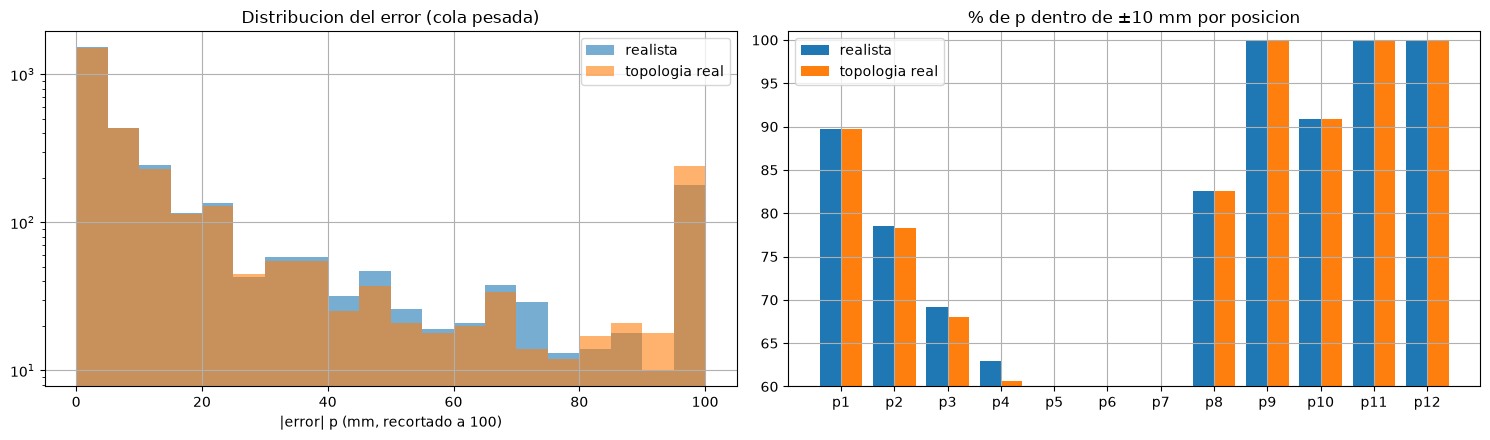

In [20]:
real_matrix = df_test[P_COLUMNS].fillna(0.0).to_numpy(float)
pred_matrix_r = design_real[P_COLUMNS].to_numpy(float)
pred_matrix_t = design_true[P_COLUMNS].to_numpy(float)
active_m = real_matrix > 0

err_r = np.abs(pred_matrix_r - real_matrix)[active_m]
err_t = np.abs(pred_matrix_t - real_matrix)[active_m]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.arange(0, 105, 5)
ax[0].hist(np.clip(err_r, 0, 100), bins=bins, alpha=0.6, label="realista")
ax[0].hist(np.clip(err_t, 0, 100), bins=bins, alpha=0.6, label="topologia real")
ax[0].set_yscale("log"); ax[0].set_xlabel("|error| p (mm, recortado a 100)"); ax[0].set_title("Distribucion del error (cola pesada)")
ax[0].legend(); ax[0].grid(True)

def pct10(pred):
    return [100 * np.mean(np.abs(pred[active_m[:, j], j] - real_matrix[active_m[:, j], j]) <= 10)
            if active_m[:, j].any() else np.nan for j in range(N_Y)]

x = np.arange(N_Y)
ax[1].bar(x - 0.2, pct10(pred_matrix_r), 0.4, label="realista")
ax[1].bar(x + 0.2, pct10(pred_matrix_t), 0.4, label="topologia real")
ax[1].set_xticks(x); ax[1].set_xticklabels(P_COLUMNS); ax[1].set_ylim(60, 101)
ax[1].set_title("% de p dentro de ±10 mm por posicion"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 16. Casos extremos

In [21]:
abs_err = np.abs(pred_matrix_r - real_matrix)
abs_err[~active_m] = np.nan
extreme = pd.DataFrame({
    "indice_test": np.arange(len(df_test)),
    "UNICODE": df_test["UNICODE"].to_numpy() if "UNICODE" in df_test else np.arange(len(df_test)),
    "BEAM": df_test["BEAM"].to_numpy(),
    "COLUMN": df_test["COLUMN"].to_numpy(),
    "max_error_mm": np.nanmax(abs_err, axis=1),
    "mean_error_mm": np.nanmean(abs_err, axis=1),
    "peor_p": np.nanargmax(abs_err, axis=1) + 1,
    "n_alma_real": df_test["n_alma"].astype(int).to_numpy(),
    "n_alma_pred": design_real["n_alma"].astype(int).to_numpy(),
    "n_cantonera_real": df_test["n_cantonera"].astype(int).to_numpy(),
    "n_cantonera_pred": design_real["n_cantonera"].astype(int).to_numpy(),
})
extreme["topologia_correcta"] = (
    (extreme.n_alma_real == extreme.n_alma_pred) & (extreme.n_cantonera_real == extreme.n_cantonera_pred)
)
extreme = extreme.sort_values("max_error_mm", ascending=False)
display(extreme.head(25).round(2))
print("Entre las 40 peores conexiones, con topologia incorrecta:", int((~extreme.head(40).topologia_correcta).sum()))

,indice_test,UNICODE,BEAM,COLUMN,max_error_mm,mean_error_mm,peor_p,n_alma_real,n_alma_pred,n_cantonera_real,n_cantonera_pred,topologia_correcta
663,663,663,IPE500,HEB700,315.0,128.33,2,2,3,0,3,False
51,51,51,HEB600,HEB800,210.0,81.25,6,4,4,3,0,False
619,619,619,HEA400,HEB700,190.0,57.86,6,3,3,3,2,False
48,48,48,HEB500,HEB450,190.0,60.71,7,3,3,3,0,False
625,625,625,HEA400,HEB650,190.0,57.86,6,3,3,3,2,False
49,49,49,HEB500,HEB500,190.0,61.43,7,3,3,3,0,False
45,45,45,HEB450,HEB400,185.0,61.67,6,3,3,2,0,False
47,47,47,HEB500,HEB400,185.0,59.29,7,3,3,3,0,False
29,29,29,HEA500,HEA500,175.0,57.14,7,3,3,3,0,False
657,657,657,IPE330,HEA400,175.0,79.17,5,3,2,2,2,False


Entre las 40 peores conexiones, con topologia incorrecta: 39


## 17. Confianza de las p (solo v4) y triaje

`prob_dentro_10` es la masa de probabilidad a ≤ ±10 mm de la moda. Si está bien calibrada, sirve para **marcar conexiones que un ingeniero debería revisar**.

In [22]:
print("Modelo por zonas: la calibracion p_logits de V14 no aplica directamente.\n"
      "Se puede anadir despues una calibracion por separado para p_viga y p_cantonera.")


Modelo por zonas: la calibracion p_logits de V14 no aplica directamente.
Se puede anadir despues una calibracion por separado para p_viga y p_cantonera.


## 18. Comprobación con el adapter de producción

Pasa las features de test por `adapter.predict` (el mismo camino que usará el servidor, sin teacher forcing) y comprueba que coincide con la inferencia realista de este notebook. Detecta discrepancias entre el decodificado del notebook y `core/postprocess.py`.

In [23]:
try:
    model.eval()
    bundle = {"model": model, "pre": pre, "device": DEVICE}
    prod = adapter.predict(df_test[list(dict.fromkeys(RAW_INPUT_COLUMNS + NUMERIC_FEATURES))], bundle)

    checks = {
        "n_alma": np.array_equal(prod["n_alma"].astype(int), design_real["n_alma"].astype(int)),
        "n_cantonera": np.array_equal(prod["n_cantonera"].astype(int), design_real["n_cantonera"].astype(int)),
        "Bolt": np.array_equal(prod["Bolt"].astype(int), design_real["Bolt"].astype(int)),
        "standard": np.array_equal(prod["standard"].astype(str), design_real["standard"].astype(str)),
        "p1..p12": np.allclose(prod[P_COLUMNS].to_numpy(float), design_real[P_COLUMNS].to_numpy(float)),
        "g,e,d,Bp,tp": np.allclose(prod[REGRESSION_ALWAYS].to_numpy(float), design_real[REGRESSION_ALWAYS].to_numpy(float)),
        "tws,ts,tbs,tst": np.allclose(prod[STIFFENER_COLUMNS].to_numpy(float), design_real[STIFFENER_COLUMNS].to_numpy(float)),
    }
    print(pd.Series(checks).to_string())
except Exception as exc:
    print("No se pudo ejecutar la comprobacion con el adapter:", type(exc).__name__, exc)

No se pudo ejecutar la comprobacion con el adapter: KeyError "['UNICODE'] not in index"


## 19. Guardado de artefactos

`weights.pt` + `preprocessor.joblib` son los dos ficheros que carga `adapter.load()`; se guardan también como `model_final.pt`. Se guarda además el dataset ya completado (con `b/tf/tw` y `Normativas`) para no repetir el paso 3.

In [24]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "cfg": CFG,
    "best_epoch": history["best_epoch"],
    "n_p_bins": N_BINS,
    "p_bin_step_mm": Y_GRID_STEP,
    "cat_cardinalities": pre.cat_cardinalities,
    "numeric_features": list(NUMERIC_FEATURES),
    "n_standard_classes": pre.n_standard_classes,
    "hidden_dim": HIDDEN_DIM, "num_blocks": NUM_BLOCKS, "dropout": DROPOUT, "gru_hidden_dim": GRU_HIDDEN_DIM,
    "p_mean_mm": pre.masked_mean[:N_Y], "p_std_mm": pre.masked_std[:N_Y],
    "reg_mean_mm": pre.reg_always_scaler.mean_, "reg_std_mm": pre.reg_always_scaler.scale_,
}
torch.save(checkpoint, OUTPUT_DIR / "model_final.pt")
torch.save(checkpoint, OUTPUT_DIR / "weights.pt")            # nombre que espera adapter.load()
joblib.dump(pre, OUTPUT_DIR / "preprocessor.joblib")
joblib.dump(history, OUTPUT_DIR / "history.joblib")
design_real.to_parquet(OUTPUT_DIR / "test_predictions.parquet", index=False)
df.to_parquet(OUTPUT_DIR / "datos_modelo_completo.parquet", index=False)

with pd.ExcelWriter(OUTPUT_DIR / "metricas.xlsx", engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="resumen_p")
    metrics_true.to_excel(writer, sheet_name="topologia_real", index=False)
    metrics_realistic.to_excel(writer, sheet_name="inferencia_realista", index=False)
    classification_metrics.to_excel(writer, sheet_name="clasificaciones", index=False)
    topology_contribution.to_excel(writer, sheet_name="contribucion_topologia", index=False)
    bias_table.to_excel(writer, sheet_name="sesgo_p", index=False)
    position_table.to_excel(writer, sheet_name="posicion_acumulada", index=False)
    transition_summary.to_excel(writer, sheet_name="transiciones", index=False)
    extreme.to_excel(writer, sheet_name="casos_extremos", index=False)
print("Artefactos en:", OUTPUT_DIR.resolve())

Artefactos en: C:\Users\jabal\OtrosProyectos\proyecto_uniones\V_px_en_cols_distintas\artifacts_px_en_cols_distintas


## 20. Ablación escalonada con varias semillas (opcional)

Cada paso cambia **una cosa** respecto al anterior (A→E). Activa `RUN_ABLATION = True` en la sección 1. Con 3 semillas son 15 entrenamientos; reduce `EPOCHS` para una comparación rápida. Las semillas cambian inicialización y orden de lotes, no la partición.

| | modelo | pesos de clase | topología | selección de época |
|---|---|---|---|---|
| A | v3 original | sí | independiente | `val_loss` |
| B | v3 | **no** | independiente | `val_loss` |
| C | **v4 (p discreta)** | no | independiente | `val_loss` |
| D | v4 | no | **conjunta** | `val_loss` |
| E | v4 | no | conjunta | **`p_and_topology`** |

In [25]:
ABLATION_CONFIGS = {
    "A_v3_original": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": True, "select_metric": "val_loss"},
    "B_v3_sin_pesos": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
    "C_v4_p_discreta": {**DEFAULT_CFG, "model": "v4", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
    "D_v4_topologia_conjunta": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "val_loss"},
    "E_v4_seleccion_por_p": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "p_and_topology"},
}

if RUN_ABLATION:
    ablation_rows = []
    for name, cfg in ABLATION_CONFIGS.items():
        for seed in ABLATION_SEEDS:
            set_seed(seed)
            m, crit = build_experiment(cfg)
            fit(m, train_loader, val_loader, crit, DEVICE, epochs=EPOCHS, lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, checkpoint_path=None, log_every=10**9,
                select_metric=cfg["select_metric"], verbose=False)
            _, _, d_true, d_real = predict_designs(m, test_loader, df_test)
            ablation_rows.append({"config": name, "seed": seed, **kpis(df_test, d_real, d_true)})
            print(f"{name} seed={seed}: p<=10mm {ablation_rows[-1]['p_pct_10mm']:.1f}% | "
                  f"topologia {ablation_rows[-1]['topologia_exacta_%']:.1f}%")
    ablation = pd.DataFrame(ablation_rows)
    agg = ablation.groupby("config").agg(["mean", "std"]).drop(columns="seed")
    display(agg.round(2))
    ablation.to_csv(OUTPUT_DIR / "ablacion.csv", index=False)
else:
    print("RUN_ABLATION=False: omitida.")

RUN_ABLATION=False: omitida.
